# 2.0 Limpieza, EDA y versiones con los módulos del proyecto

Este notebook ya no contiene lógica propia: llama a las funciones de `mibici` y muestra sus resultados. La tubería completa se corre con `make pipeline`.

In [1]:
import mlflow
import pandas as pd
from IPython.display import Image, display

from mibici.cleaning import CleaningRules, TripCleaner
from mibici.config import FIGURES_DIR, MLFLOW_TRACKING_URI, PROCESSED_DATA_DIR
from mibici.dataset import load_raw_trips, load_stations

from loguru import logger
logger.disable('mibici')

raw, archivos = load_raw_trips()
stations = load_stations()
pd.DataFrame([vars(a) for a in archivos]).assign(sha256=lambda d: d.sha256.str[:12])

/home/fgrodriguez/mibici-mlops/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-23 15:36:20.601 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/fgrodriguez/mibici-mlops


,name,encoding,rows,sha256
0,datos_abiertos_2025_01.csv,latin-1,380184,90ee75701a69
1,datos_abiertos_2025_02.csv,latin-1,372529,f52f13f59eb2
2,datos_abiertos_2025_03.csv,utf-8,405110,e5aa1b5d197f
3,datos_abiertos_2025_04.csv,utf-8,366193,630e637d6611
4,datos_abiertos_2025_05.csv,utf-8,395891,e0a744412a1e
5,datos_abiertos_2025_06.csv,utf-8,356611,063e3523db00
6,datos_abiertos_2025_07.csv,latin-1,368186,a71a9e2a629f
7,datos_abiertos_2025_08.csv,utf-8,374727,382e62f3eb87
8,datos_abiertos_2025_09.csv,utf-8,376789,218bed1587a7
9,datos_abiertos_2025_10.csv,utf-8,420064,505d9b8b59f6


## Limpieza

Reporte de cada regla de la variante estricta.

In [2]:
cleaner = TripCleaner(CleaningRules.variant('estricta'), set(stations['estacion_id']))
clean = cleaner.clean(raw)
cleaner.report_frame()

,regla,accion,filas_afectadas,filas_tras
0,filas_crudas,ninguna,0,4532032
1,viaje_id_duplicado,eliminar,0,4532032
2,fecha_invalida,eliminar,0,4532032
3,id_no_numerico,eliminar,0,4532032
4,estacion_fuera_de_catalogo,eliminar,0,4532032
5,genero_nulo,imputar 'Desconocido',40789,4532032
6,anio_nacimiento_invalido,dejar nulo,1646,4532032
7,duracion_no_positiva,eliminar,2780,4529252
8,arranque_fallido,eliminar,123158,4406094
9,duracion_muy_corta,eliminar,5807,4400287


In [3]:
print(f'{len(raw) - len(clean):,} viajes eliminados '
      f'({100 * (len(raw) - len(clean)) / len(raw):.2f} %)')
clean.dtypes

132,199 viajes eliminados (2.92 %)


viaje_id                         int64
usuario_id                       int64
genero                        category
anio_nacimiento                  Int64
inicio                  datetime64[us]
fin                     datetime64[us]
origen_id                        int64
destino_id                       int64
edad                             Int64
duracion_min                   float64
mismo_origen_destino              bool
dtype: object

## Estadísticas descriptivas

In [4]:
clean[['duracion_min', 'edad']].astype(float).describe().round(2)

,duracion_min,edad
count,4399833.00,4398234.00
mean,11.43,34.56
std,7.21,11.00
min,1.00,16.00
25%,6.18,26.00
50%,9.85,32.00
75%,15.17,40.00
max,179.37,86.00


In [5]:
demanda = pd.read_parquet(PROCESSED_DATA_DIR / 'demanda_estacion_hora_estricta.parquet')
demanda[['salidas', 'llegadas', 'neto']].describe().round(3)

,salidas,llegadas,neto
count,3249960.000,3249960.000,3249960.000
mean,1.354,1.354,-0.000
std,2.464,2.605,1.946
min,0.000,0.000,-71.000
25%,0.000,0.000,0.000
50%,0.000,0.000,0.000
75%,2.000,2.000,0.000
max,202.000,207.000,100.000


El máximo de 202 salidas en una hora se aleja mucho del percentil 75 (2 salidas). Se revisan los casos extremos antes de decidir si son errores.

In [6]:
demanda.nlargest(5, 'salidas').merge(stations[['estacion_id', 'nombre']], how='left')

,estacion_id,fecha_hora,salidas,llegadas,neto,nombre
0,194,2025-09-20 21:00:00,202,207,5,(GDL-127) Av. Vallarta / Av. de Los Arcos
1,194,2025-09-20 20:00:00,172,175,3,(GDL-127) Av. Vallarta / Av. de Los Arcos
2,194,2025-11-01 21:00:00,106,99,-7,(GDL-127) Av. Vallarta / Av. de Los Arcos
3,50,2025-09-20 20:00:00,103,113,10,(GDL-048) C. Constancio Hernández/ Av. Juaréz
4,46,2025-09-20 20:00:00,94,94,0,(GDL-044) C. Gral. San Martín /Av. Vallarta


Los picos se concentran en una estación la noche del sábado 20 de septiembre, con salidas y llegadas casi iguales: parece un evento masivo de ida y vuelta, no un error de captura. Se conservan en los datos y se marcan como candidatos para la detección de anomalías en fases posteriores.

## Visualizaciones

Generadas por `python -m mibici.plots`.

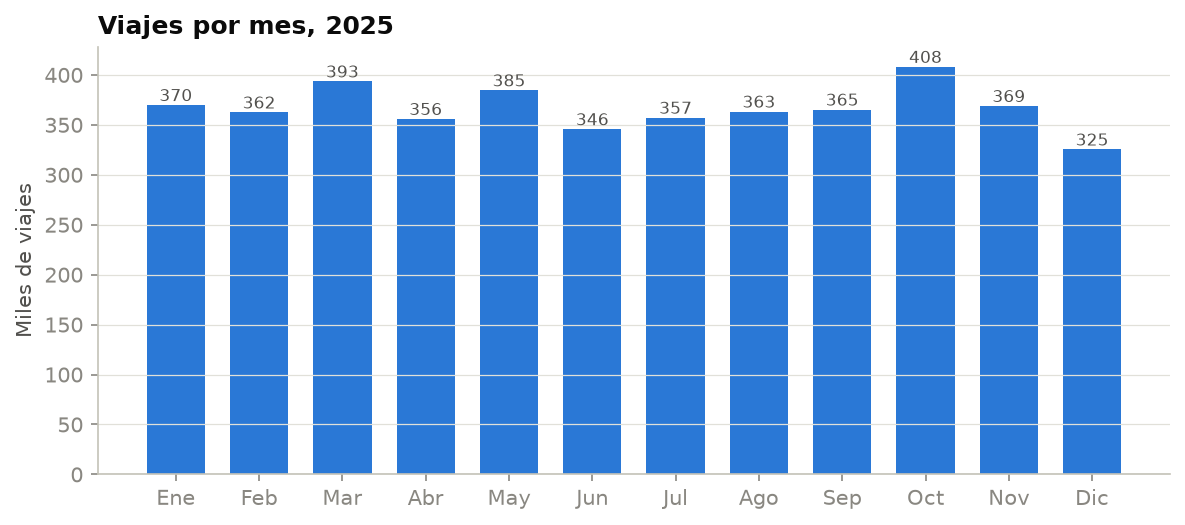

In [7]:
display(Image(FIGURES_DIR / '01_viajes_por_mes.png'))

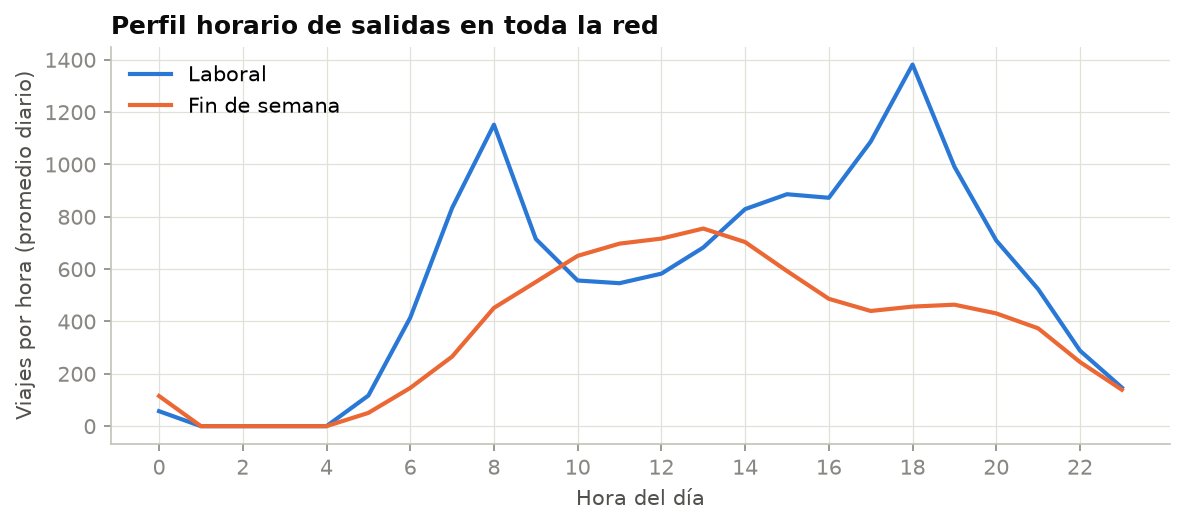

In [8]:
display(Image(FIGURES_DIR / '02_perfil_horario.png'))

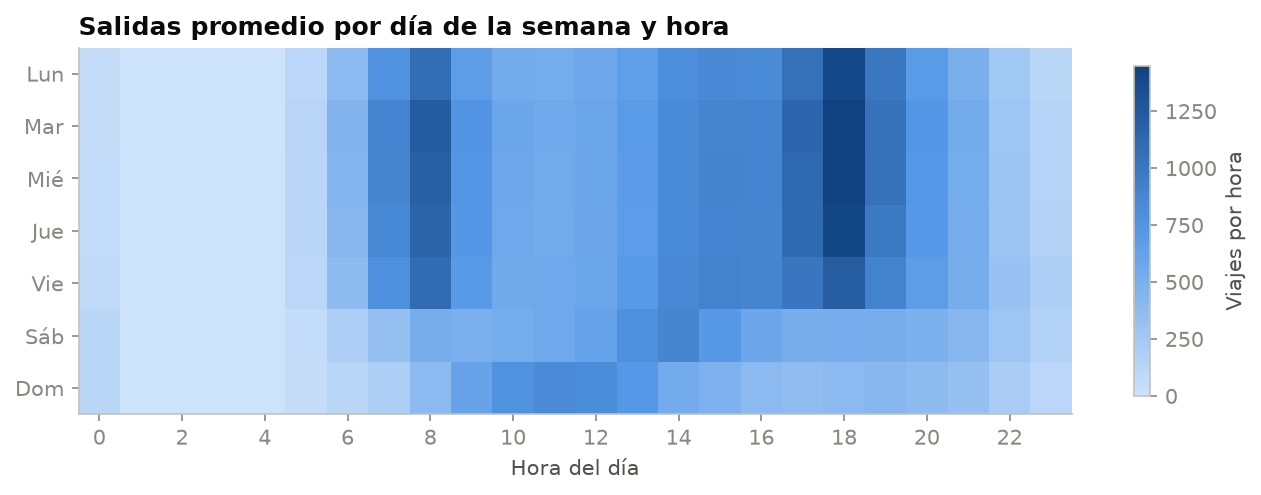

In [9]:
display(Image(FIGURES_DIR / '03_mapa_calor_dia_hora.png'))

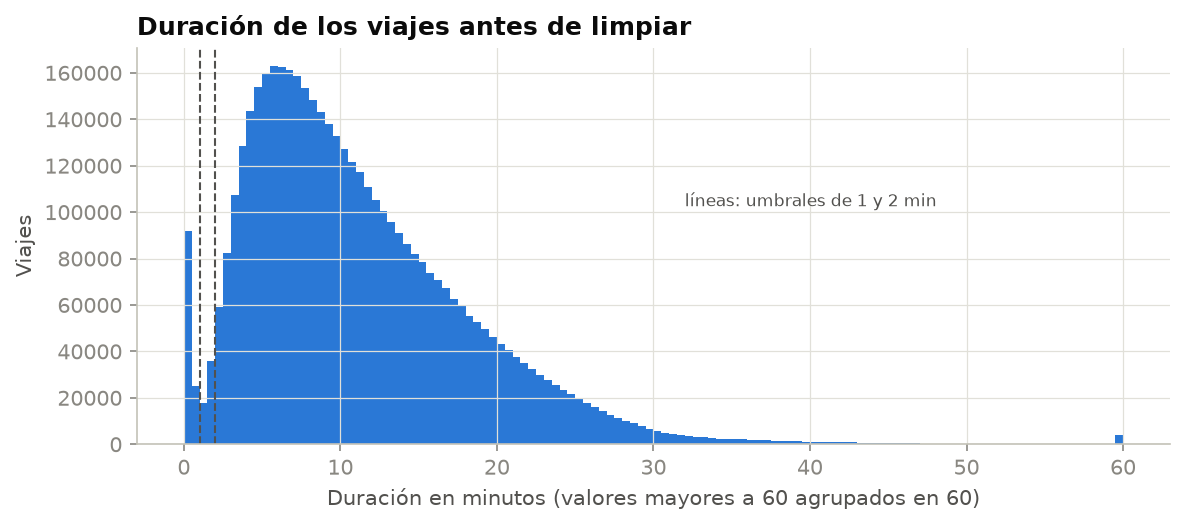

In [10]:
display(Image(FIGURES_DIR / '04_duracion_viajes.png'))

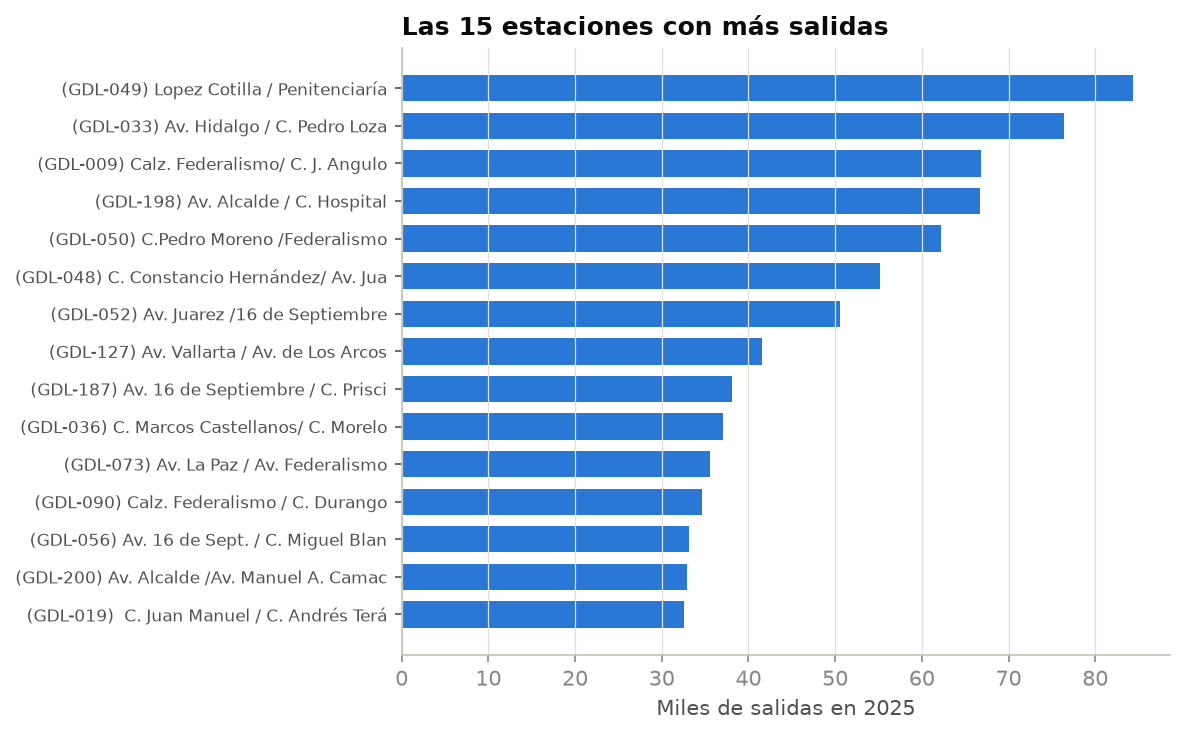

In [11]:
display(Image(FIGURES_DIR / '05_top_estaciones.png'))

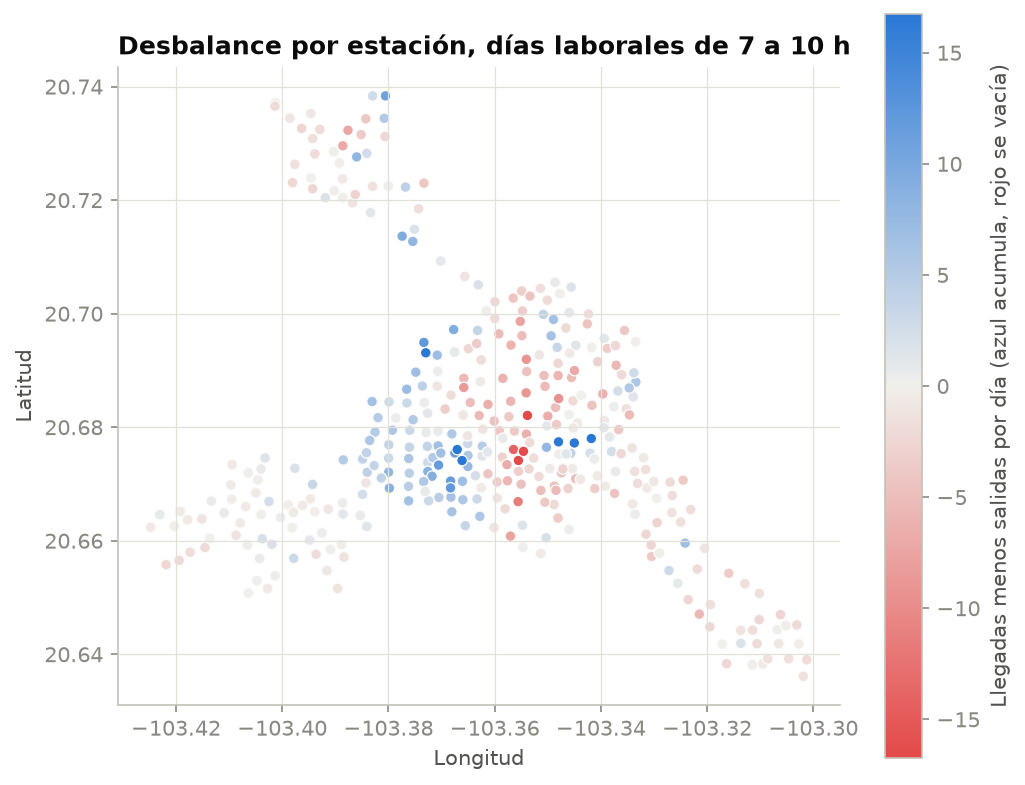

In [12]:
display(Image(FIGURES_DIR / '06_mapa_desbalance_manana.png'))

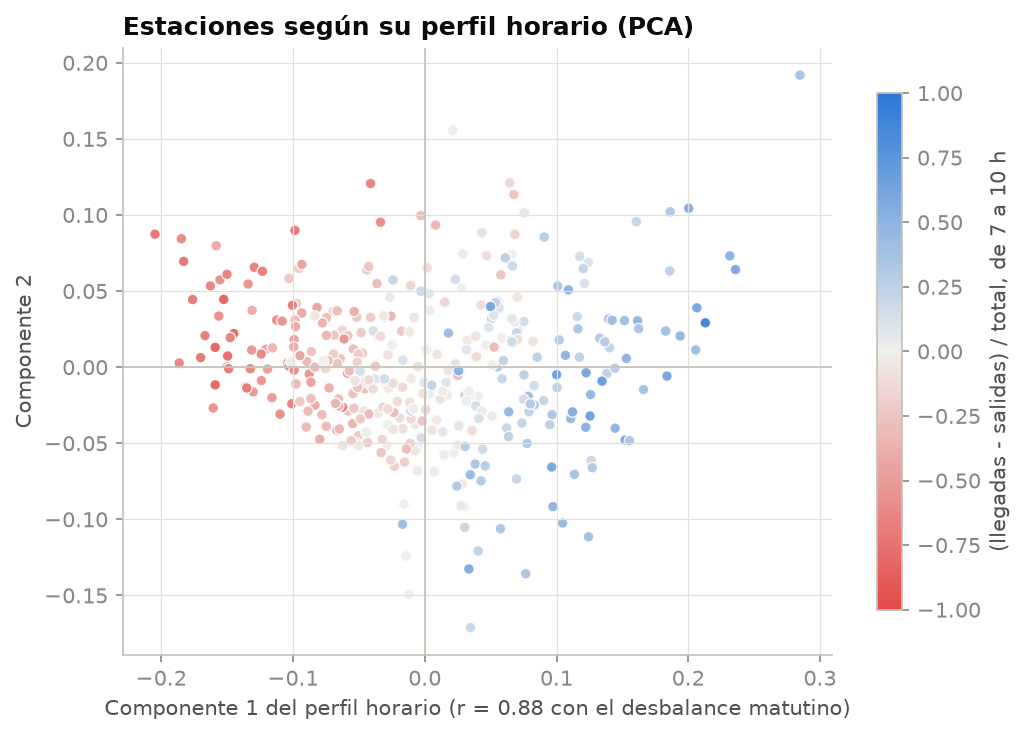

In [13]:
display(Image(FIGURES_DIR / '07_pca_perfiles.png'))

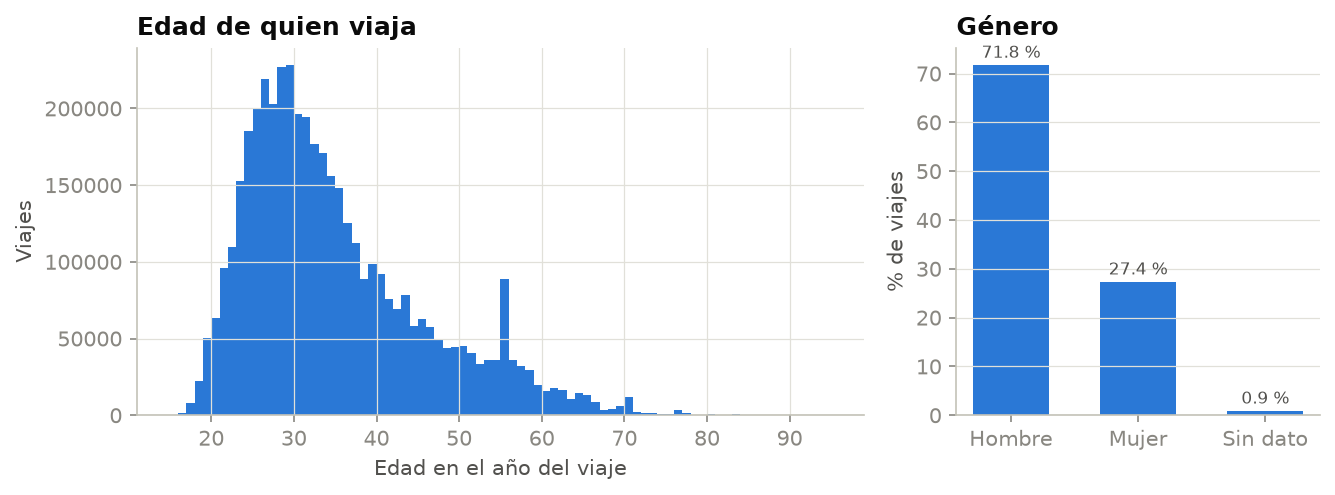

In [14]:
display(Image(FIGURES_DIR / '08_usuarios.png'))

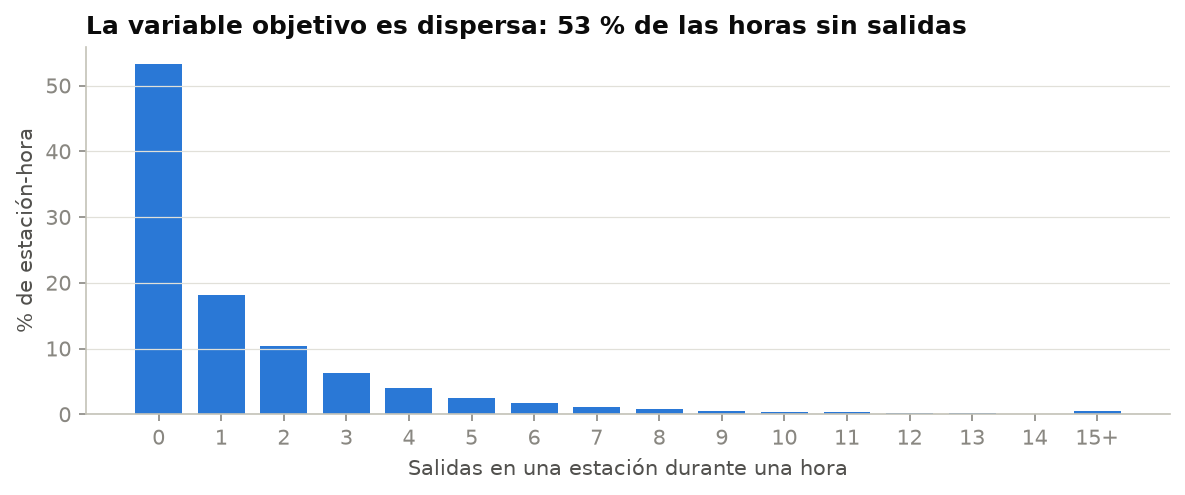

In [15]:
display(Image(FIGURES_DIR / '09_distribucion_objetivo.png'))

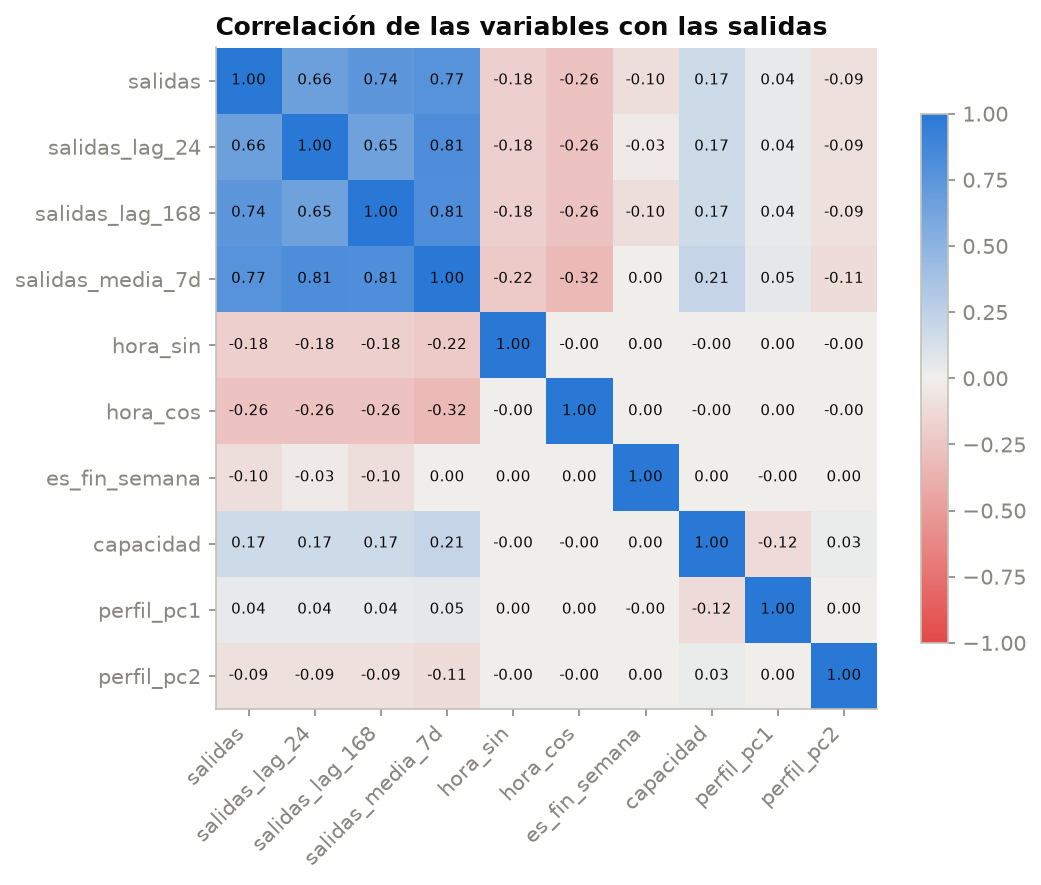

In [16]:
display(Image(FIGURES_DIR / '10_correlaciones.png'))

## Preprocesamiento

El preprocesador se ajusta solo con entrenamiento (enero a octubre) y se guarda como artefacto en la versión v3.

In [17]:
from mibici.features import build_preprocessor
variables = pd.read_parquet(PROCESSED_DATA_DIR / 'variables_estricta.parquet')
train = variables[variables['particion'] == 'entrenamiento']
prep = build_preprocessor().fit(train)
X = prep.transform(train)
print('filas:', X.shape[0], ' columnas tras escalar y codificar:', X.shape[1])
list(prep.get_feature_names_out())

filas: 2644488  columnas tras escalar y codificar: 26


['numericas__hora',
 'numericas__hora_sin',
 'numericas__hora_cos',
 'numericas__salidas_lag_24',
 'numericas__salidas_lag_168',
 'numericas__salidas_media_7d',
 'numericas__llegadas_lag_24',
 'numericas__llegadas_lag_168',
 'numericas__llegadas_media_7d',
 'numericas__latitud',
 'numericas__longitud',
 'numericas__capacidad',
 'numericas__perfil_pc1',
 'numericas__perfil_pc2',
 'binarias__es_fin_semana',
 'binarias__es_festivo',
 'categoricas__dia_semana_0',
 'categoricas__dia_semana_1',
 'categoricas__dia_semana_2',
 'categoricas__dia_semana_3',
 'categoricas__dia_semana_4',
 'categoricas__dia_semana_5',
 'categoricas__dia_semana_6',
 'categoricas__zona_GDL',
 'categoricas__zona_TLQ',
 'categoricas__zona_ZPN']

## Versiones registradas en MLflow

In [18]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=['MiBici_Fase1_Versiones_Datos'])
cols = ['tags.mlflow.runName', 'tags.estado', 'params.filas', 'metrics.pct_eliminado', 'metrics.pca_varianza_pc1', 'tags.sha256']
runs[cols].assign(**{'tags.sha256': runs['tags.sha256'].str[:12], 'tags.estado': runs['tags.estado'].fillna('vigente')}).sort_values('tags.mlflow.runName')

,tags.mlflow.runName,tags.estado,params.filas,metrics.pct_eliminado,metrics.pca_varianza_pc1,tags.sha256
8,v0_crudo,vigente,4532032,NaN,NaN,3bbd269b92e5
7,v1_limpio_estricta,vigente,4399833,2.916992,NaN,275225e44f84
6,v1_limpio_laxa,vigente,4529246,0.061474,NaN,0fe5b58608e0
5,v2_demanda_estricta,vigente,3249960,NaN,NaN,9657866cd640
3,v2_demanda_laxa,vigente,3249960,NaN,NaN,8b3b5008d621
1,v3_variables_estricta,vigente,3187632,NaN,0.340690,bd2933f487bd
4,v3_variables_estricta,descartada,3187632,NaN,0.190151,712f680a2370
0,v3_variables_laxa,vigente,3187632,NaN,0.332447,e4b6ab993647
2,v3_variables_laxa,descartada,3187632,NaN,0.182598,dedb8530e223


## Experimento: ¿cambia la limpieza la señal?

In [19]:
exp = mlflow.search_runs(experiment_names=['MiBici_Fase1_Experimentos_Datos'])
exp = exp[exp['tags.estado'].ne('descartada')]
m = [c for c in exp.columns if c.startswith('metrics.salidas')]
exp.set_index('params.variante_datos')[m].T.round(3)

params.variante_datos,laxa,estricta
metrics.salidas_promedio_historico_mae,0.837,0.828
metrics.salidas_misma_hora_semana_pasada_mae,0.974,0.954
metrics.salidas_misma_hora_semana_pasada_mae_pico,1.586,1.551
metrics.salidas_promedio_historico_mae_pico,1.442,1.420
metrics.salidas_promedio_historico_rmse,1.502,1.489
metrics.salidas_misma_hora_semana_pasada_rmse,1.880,1.834
